# M1 - 20-class single-object classification: comparing 4 architectures

Implement and compare at least 3 **distinct** network architectures suited to images; retraining the same architecture with different hyperparameters counts as one model. The report gives the performance of each model and states which one is best and why.

This notebook covers the following tasks:

| Task | Content |
|---|---|
| 1 | Configuration, Google Drive |
| 2 | Import and check the dataset (statistics, duplicates, format conversion, thumbnails) |
| 3 | Class map `classes.json` |
| 4 | Near-duplicate grouping + stratified split → `split_manifest.csv` (reused by M2) |
| 5 | Data pipeline and augmentation |
| 6 | 4 models: custom CNN, MobileNetV2, ResNet-50, EfficientNet-B0 |
| 7 | Training (pretrained models in two stages: frozen backbone → fine-tune the top blocks) |
| 8 | Select the best model on **validation only**, and save the decision first |
| 9 | Only then evaluate all models on test: comparison table, confusion matrices, misclassified examples |
| 10 | Run records (JSON/CSV) |

## Before running (once)

1. Open the shared folder link → **"Add shortcut to Drive"** → put it in the root of "My Drive". The shortcut is usually called `student uploaded files`; if not, change `DATA_DIR` in Task 1.
2. Colab menu **Runtime → Change runtime type → T4 GPU**.
3. **Runtime → Run all**. Results are saved to `IE7615_project/runs/m1_<time>/` on Drive, so they survive the end of the session.

Expected time: data preparation about 5–10 min (copying images from Drive); training the 4 models about 20–40 min on a T4.

# Task1 - Configuration and Google Drive

In [1]:
import os, sys, json, time, uuid, hashlib, shutil, zipfile, platform, re, csv, subprocess, math
from pathlib import Path
from datetime import datetime, timezone

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # iPhone photos may be HEIC; Pillow needs the pillow-heif plugin to open them
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pillow-heif"], check=False)

import numpy as np
from PIL import Image, ImageOps, ImageDraw
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
    HEIF_OK = True
except ImportError:
    HEIF_OK = False

import matplotlib
if not IN_COLAB:
    matplotlib.use("Agg")      # no screen when run from the command line (smoke test)
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import tensorflow as tf
import keras
from keras import layers
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
if IN_COLAB and not tf.config.list_physical_devices("GPU"):
    print("⚠️ No GPU: choose Runtime → Change runtime type → T4 GPU, otherwise the pretrained models are very slow.")

TensorFlow 2.21.0 | Keras 3.13.2 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Smoke test: few images, 1 epoch, no pretrained weights download (set M1_SMOKE=1 to check the code runs)
SMOKE = os.environ.get("M1_SMOKE") == "1"

SEED = 42
SPLIT_RATIOS = (0.70, 0.15, 0.15)   # train / val / test
IMG_SIZE = 224                      # input size of all 4 models
BATCH = 32
PHASH_THRESHOLD = 4                 # pHash Hamming distance <= 4 (at most 4 of 64 bits differ) = near-duplicate
WEIGHT_DECAY = 1e-4
PRETRAINED = None if SMOKE else "imagenet"
EPOCHS = dict(cnn=60, head=10, finetune=20)
PATIENCE = dict(cnn=10, finetune=5)              # early-stopping patience (epochs)
LR = dict(cnn=1e-3, head=1e-3, finetune=1e-4)   # fine-tuning LR is 10x lower than head training
MAX_PER_CLASS = None
if SMOKE:
    EPOCHS = dict(cnn=1, head=1, finetune=1)
    MAX_PER_CLASS = 20

MODEL_NAMES = ["custom_cnn", "mobilenetv2", "resnet50", "efficientnetb0"]

In [4]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/data/student uploaded files")  # shortcut to the shared folder
    OUT_ROOT = Path("/content/drive/MyDrive/data/IE7615_project/runs")     # results on Drive survive the session
    WORK_DIR = Path("/content/m1_data")                               # local copy of the images, faster to read
else:
    DATA_DIR = Path(os.environ.get("M1_DATA_DIR", "data/raw"))
    OUT_ROOT = Path(os.environ.get("M1_OUT_ROOT", "runs"))
    WORK_DIR = Path(os.environ.get("M1_WORK_DIR", "m1_data"))

# Code version: fill in the GitHub repo and commit so the run records contain the commit.
# Easiest: open this commit's notebook in Colab directly from GitHub
#   https://colab.research.google.com/github/<user>/<repo>/blob/<commit>/m1/<notebook>.ipynb
# so the running code and the recorded commit are the same version. Never put access tokens in the notebook.
REPO_URL = ""      # e.g. "https://github.com/<user>/<repo>.git"; empty → commit recorded as "not recorded"
REPO_COMMIT = ""   # e.g. "a1b2c3d"; empty → latest commit of the default branch
REPO_DIR = Path(os.environ.get("M1_REPO_DIR", ".")) if not IN_COLAB else None
if IN_COLAB and REPO_URL:
    REPO_DIR = Path("/content/repo")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
    if REPO_COMMIT:
        subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "-q", REPO_COMMIT], check=True)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Data folder {DATA_DIR} not found. Add a shortcut to the shared folder in 'My Drive', or change DATA_DIR.")

# Each run gets its own output folder: data / models / figures / records
RUN_TAG = datetime.now().strftime("m1_%Y%m%d_%H%M%S") + ("_smoke" if SMOKE else "")
OUT_DIR = OUT_ROOT / RUN_TAG
for sub in ["data", "models", "figures", "records"]:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)
if WORK_DIR.exists():
    shutil.rmtree(WORK_DIR)
WORK_DIR.mkdir(parents=True)
print("Data folder:  ", DATA_DIR)
print("Output folder:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data folder:   /content/drive/MyDrive/data/student uploaded files
Output folder: /content/drive/MyDrive/data/IE7615_project/runs/m1_20261018_022316


# Task2 - Import and check the dataset

## a: find the class folders and zip files

In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp", ".heic", ".heif", ".tif", ".tiff"}
KEEP_EXT = {".jpg", ".jpeg", ".png"}            # TensorFlow decodes these directly, so they are copied as is
CLASS_RE = re.compile(r"images_(OBJ\d+)", re.I)
issues = []                                      # every data problem that the report should mention

def file_hash(path, algo="md5"):
    h = hashlib.new(algo)
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):   # read 1 MB at a time
            h.update(chunk)
    return h.hexdigest()

def is_image_name(name):
    # skip hidden files and macOS "__MACOSX" folders inside zips
    parts = Path(name).parts
    return (Path(name).suffix.lower() in IMG_EXT and not any(p.startswith((".", "__MACOSX")) for p in parts))

# Class folders are named images_OBJxxx
class_dirs, zips = {}, []
for p in sorted(DATA_DIR.iterdir()):
    name = p.name.strip()
    if p.is_dir():
        m = CLASS_RE.fullmatch(name)
        if not m:
            issues.append(f"Ignored unknown folder: {p.name!r}")
            continue
        cid = m.group(1).upper()
        if name != p.name:
            issues.append(f"Folder name had leading/trailing spaces, removed: {p.name!r} → {cid}")
        if cid in class_dirs:
            issues.append(f"{cid} has several folders, only the first is used: {class_dirs[cid].name!r}, ignored {p.name!r}")
            continue
        class_dirs[cid] = p
    elif p.suffix.lower() == ".zip":
        zips.append(p)

# A zip is compared with the folder of the same class; it is unzipped and used only if there is no folder
for zp in zips:
    m = CLASS_RE.fullmatch(zp.stem.strip())
    if not m:
        issues.append(f"Ignored unknown zip: {zp.name!r}")
        continue
    cid = m.group(1).upper()
    with zipfile.ZipFile(zp) as zf:
        members = [n for n in zf.namelist() if is_image_name(n) and not n.endswith("/")]
        zip_md5 = {hashlib.md5(zf.read(n)).hexdigest() for n in members}
        if cid in class_dirs:
            folder_md5 = {file_hash(f) for f in class_dirs[cid].rglob("*") if f.is_file() and is_image_name(f.name)}
            both, only_zip, only_folder = len(zip_md5 & folder_md5), len(zip_md5 - folder_md5), len(folder_md5 - zip_md5)
            issues.append(f"{zp.name}: compared with folder {cid}: {both} identical, {only_zip} only in zip, {only_folder} only in folder. "
                          f"Folder used, zip not used" + (" (zip has images the folder lacks, check by hand)" if only_zip else " (zip is a duplicate)"))
        else:
            dest = WORK_DIR / "_unzipped" / cid
            zf.extractall(dest, members=members)
            class_dirs[cid] = dest
            issues.append(f"{cid} has only a zip and no folder; unzipped and used {zp.name}")

CLASS_IDS = sorted(class_dirs)
print(f"Found {len(CLASS_IDS)} classes: {CLASS_IDS}")

Found 20 classes: ['OBJ000', 'OBJ001', 'OBJ002', 'OBJ004', 'OBJ006', 'OBJ007', 'OBJ011', 'OBJ070', 'OBJ108', 'OBJ111', 'OBJ123', 'OBJ125', 'OBJ201', 'OBJ222', 'OBJ523', 'OBJ529', 'OBJ608', 'OBJ666', 'OBJ777', 'OBJ916']


## b: read every image, copy it locally, convert when needed
Images that are not JPG/PNG, or that carry an EXIF rotation, are saved as PNG with the rotation applied, so every model sees the photo the right way up.

In [6]:
records = []
for cid in CLASS_IDS:
    files = sorted(f for f in class_dirs[cid].rglob("*") if f.is_file() and is_image_name(str(f.relative_to(class_dirs[cid]))))
    if MAX_PER_CLASS:
        files = files[:MAX_PER_CLASS]
    (WORK_DIR / cid).mkdir(parents=True, exist_ok=True)
    for i, f in enumerate(files):
        ext = f.suffix.lower()
        if ext in {".heic", ".heif"} and not HEIF_OK:
            issues.append(f"Skipped HEIC (pillow-heif not installed): {cid}/{f.name}")
            continue
        try:
            with Image.open(f) as im:
                im.load()                                  # fails here if the file is broken
                orient = im.getexif().get(0x0112, 1)       # EXIF tag 0x0112 = orientation, 1 = upright
                w, h, fmt = im.width, im.height, im.format
                convert = ext not in KEEP_EXT or orient not in (1, None)
                image_id = f"{cid}_{i:04d}"
                if convert:
                    out = WORK_DIR / cid / f"{image_id}.png"
                    ImageOps.exif_transpose(im).convert("RGB").save(out)
                    w, h = Image.open(out).size
                    reason = "EXIF rotation" if orient not in (1, None) else f"format {ext}"
                else:
                    out = WORK_DIR / cid / f"{image_id}{ext}"
                    shutil.copy2(f, out)
                    reason = ""
        except Exception as e:
            issues.append(f"Cannot read, skipped: {cid}/{f.name} ({type(e).__name__})")
            continue
        try:
            src_rel = str(f.relative_to(DATA_DIR))
        except ValueError:
            src_rel = f"[zip]/{f.relative_to(class_dirs[cid])}"
        records.append(dict(image_id=image_id, class_id=cid, md5=file_hash(f), width=w, height=h, format=fmt,
                            converted=reason, src_path=src_rel, local_path=str(out.relative_to(WORK_DIR)).replace("\\", "/")))
    print(f"{cid}: {sum(r['class_id'] == cid for r in records)} images")

converted = [r for r in records if r["converted"]]
if converted:
    issues.append(f"Converted {len(converted)} images to PNG (reasons: {sorted({r['converted'] for r in converted})})")

OBJ000: 100 images
OBJ001: 100 images
OBJ002: 100 images
OBJ004: 100 images
OBJ006: 100 images
OBJ007: 100 images
OBJ011: 100 images
OBJ070: 100 images
OBJ108: 100 images
OBJ111: 100 images
OBJ123: 100 images
OBJ125: 100 images
OBJ201: 100 images
OBJ222: 100 images
OBJ523: 100 images
OBJ529: 114 images
OBJ608: 108 images
OBJ666: 100 images
OBJ777: 100 images
OBJ916: 100 images


## c: exact duplicates and per-class statistics

In [7]:
# Identical files (same md5)
by_md5 = {}
for r in records:
    by_md5.setdefault(r["md5"], []).append(r)
for md5, rs in by_md5.items():
    if len(rs) > 1:
        cls = sorted({r["class_id"] for r in rs})
        kind = "across classes (possible wrong label, check by hand)" if len(cls) > 1 else "within one class"
        issues.append(f"{len(rs)} identical files, {kind}: {[r['image_id'] for r in rs]}")

def md_table(header, rows):
    # Markdown table, can be pasted into the report
    lines = ["| " + " | ".join(map(str, header)) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(map(str, r)) + " |" for r in rows]
    return "\n".join(lines)

stat_rows = []
for cid in CLASS_IDS:
    rs = [r for r in records if r["class_id"] == cid]
    sizes = {}
    for r in rs:
        sizes[(r["width"], r["height"])] = sizes.get((r["width"], r["height"]), 0) + 1
    common = max(sizes, key=sizes.get) if sizes else ("-", "-")
    stat_rows.append([cid, len(rs), f"{common[0]}×{common[1]}", len(sizes), ",".join(sorted({str(r['format']) for r in rs})),
                      sum(bool(r["converted"]) for r in rs)])
stats_md = md_table(["class", "images", "most common size", "distinct sizes", "formats", "converted"], stat_rows)
display(Markdown(stats_md))
print(f"Total: {len(records)} images, {len(CLASS_IDS)} classes")
print("\nData issues:")
for s in issues:
    print(" -", s)

| class | images | most common size | distinct sizes | formats | converted |
|---|---|---|---|---|---|
| OBJ000 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ001 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ002 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ004 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ006 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ007 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ011 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ070 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ108 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ111 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ123 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ125 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ201 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ222 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ523 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ529 | 114 | 224×224 | 1 | JPEG | 0 |
| OBJ608 | 108 | 224×224 | 1 | JPEG | 0 |
| OBJ666 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ777 | 100 | 224×224 | 1 | JPEG | 0 |
| OBJ916 | 100 | 224×224 | 1 | JPEG | 0 |

Total: 2022 images, 20 classes

Data issues:
 - Folder name had leading/trailing spaces, removed: 'images_OBJ001 ' → OBJ001
 - 2 identical files, within one class: ['OBJ007_0012', 'OBJ007_0042']
 - 2 identical files, within one class: ['OBJ007_0013', 'OBJ007_0066']
 - 2 identical files, within one class: ['OBJ007_0038', 'OBJ007_0088']
 - 2 identical files, within one class: ['OBJ125_0006', 'OBJ125_0099']


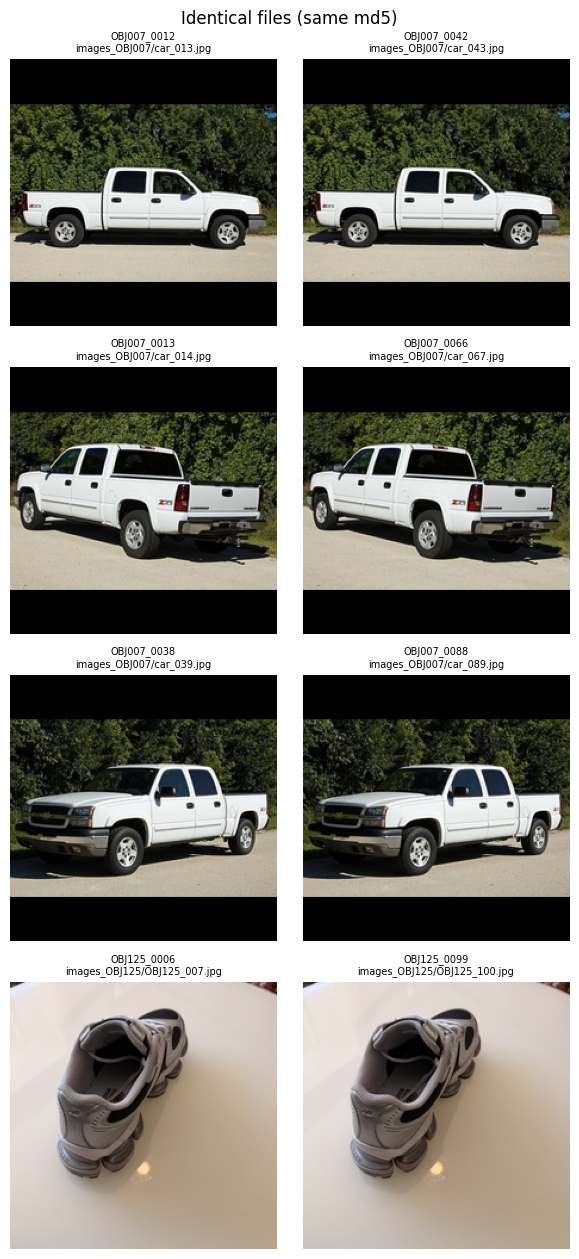

In [26]:
# Show identical files (same md5) side by side, one group per row
dup_groups = [rs for rs in by_md5.values() if len(rs) > 1]
if dup_groups:
    cols = max(len(rs) for rs in dup_groups)
    fig, axes = plt.subplots(len(dup_groups), cols, figsize=(3 * cols, 3.2 * len(dup_groups)), squeeze=False)
    for row, rs in enumerate(dup_groups):
        for col in range(cols):
            ax = axes[row][col]; ax.axis("off")
            if col < len(rs):
                with Image.open(WORK_DIR / rs[col]["local_path"]) as im:
                    ax.imshow(im.convert("RGB"))
                # Title: image ID + original file path (to find the file in Drive)
                ax.set_title(f"{rs[col]['image_id']}\n{rs[col]['src_path']}", fontsize=7)
    plt.suptitle("Identical files (same md5)")
    plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "identical_files.jpg", dpi=90); plt.show()
else:
    print("No identical files.")

## d: thumbnail overview (10 random images per class)
Look for images that show the wrong object or more than one object.

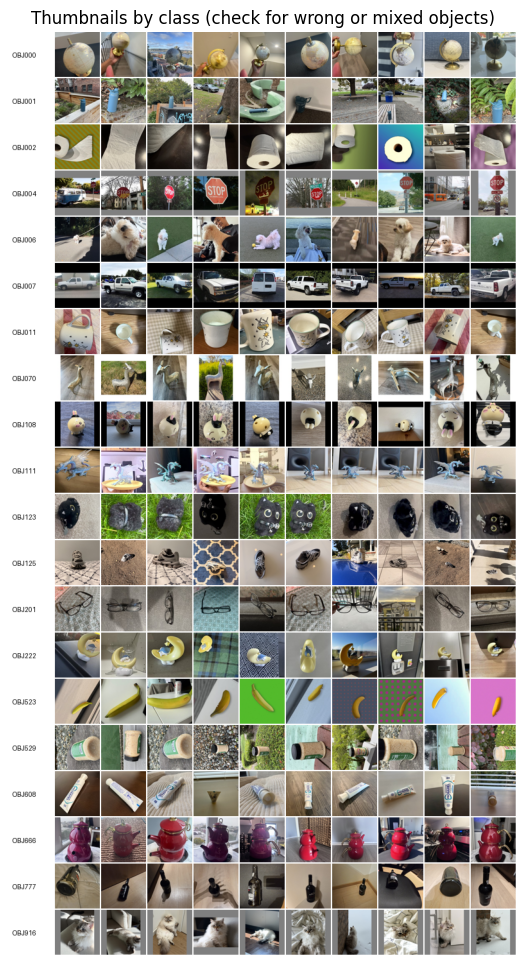

In [8]:
rng_vis = np.random.default_rng(SEED)
T, COLS, LABEL_W = 72, 10, 70      # thumbnail size, thumbnails per row, width of the label column
sheet = Image.new("RGB", (LABEL_W + COLS * T, len(CLASS_IDS) * T), "white")
draw = ImageDraw.Draw(sheet)
for row, cid in enumerate(CLASS_IDS):
    rs = [r for r in records if r["class_id"] == cid]
    pick = rng_vis.choice(len(rs), size=min(COLS, len(rs)), replace=False) if rs else []
    draw.text((4, row * T + T // 2 - 6), cid, fill="black")
    for col, k in enumerate(pick):
        with Image.open(WORK_DIR / rs[k]["local_path"]) as im:
            sheet.paste(ImageOps.fit(im.convert("RGB"), (T - 2, T - 2)), (LABEL_W + col * T, row * T))
sheet.save(OUT_DIR / "figures" / "thumbnails_by_class.jpg", quality=90)

plt.figure(figsize=(12, len(CLASS_IDS) * 0.6))
plt.imshow(sheet); plt.axis("off"); plt.title("Thumbnails by class (check for wrong or mixed objects)")
plt.show()

The dataset has 2,022 images in 20 classes (100 to 114 images per class: 18 classes have exactly 100, OBJ529 has 114 and OBJ608 has 108). Every image is a 224×224 JPEG, so no image was converted to PNG, and every file could be read. I found 4 pairs of identical files (8 files), all within the same class: 3 pairs in OBJ007 and 1 pair in OBJ125. Because identical files are put in the same near-duplicate group in Task 4, each pair stays in one split and cannot leak from train to test. The inspected thumbnails (10 random images per class) show one main object per image and no obvious labeling issues. Backgrounds vary within most classes, but a few classes have class-specific framing: OBJ007 and OBJ108 images often have black borders, OBJ070 has white borders, and several OBJ523 images use solid artificial backgrounds (green, pink, blue).

**Data issues that the report must mention: mild class imbalance (100–114 images per class); 4 duplicate pairs within OBJ007 (3) and OBJ125 (1), kept together in one split; class-specific borders and backgrounds (OBJ007, OBJ108, OBJ070, OBJ523) are a possible shortcut, because the model could recognize the framing instead of the object.**

# Task3 - Class map
The models output indices 0..N-1; outside the model I use the course IDs (OBJxxx). `classes.json` is shared with M2 (YOLO).

In [9]:
CLASSES = {i: cid for i, cid in enumerate(CLASS_IDS)}
NUM_CLASSES = len(CLASSES)
CID2IDX = {cid: i for i, cid in CLASSES.items()}
classes_path = OUT_DIR / "data" / "classes.json"
classes_path.write_text(json.dumps({str(i): cid for i, cid in CLASSES.items()}, indent=2), encoding="utf-8")
CLASSES_SHA = file_hash(classes_path, "sha256")   # checksum goes into the run records
print(f"{NUM_CLASSES} classes, classes.json sha256 = {CLASSES_SHA[:16]}…")

20 classes, classes.json sha256 = 511d30a18ee81bfa…


# Task4 - Near-duplicate grouping and stratified split
Photos taken a second apart are almost the same image. If one goes to train and the other to test, the test score is too optimistic. So near-duplicates are grouped, and a whole group always goes into the same split.

## a: perceptual hash (pHash) and cross-class check

In [10]:
def dct_matrix(n):
    # orthonormal DCT-II matrix, so that D @ a @ D.T is the 2-D DCT of a
    k = np.arange(n)
    m = np.cos(np.pi * (2 * k[None, :] + 1) * k[:, None] / (2 * n)) * np.sqrt(2 / n)
    m[0] /= np.sqrt(2)
    return m

D32 = dct_matrix(32)

def phash_bits(path):
    """pHash: grayscale 32x32 → 2-D DCT → top-left 8x8 low frequencies → compare with the median → 64 bits."""
    with Image.open(path) as im:
        a = np.asarray(im.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float64)
    low = (D32 @ a @ D32.T)[:8, :8]
    return (low > np.median(low)).flatten()

for r in records:
    r["_bits"] = phash_bits(WORK_DIR / r["local_path"])
    r["phash"] = np.packbits(r["_bits"]).tobytes().hex()
    r["class_idx"] = CID2IDX[r["class_id"]]

# Hamming distance between every pair of images (popcount of XOR)
bits = np.stack([r["_bits"] for r in records])
packed = np.packbits(bits, axis=1)
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
ham = POP[np.bitwise_xor(packed[:, None, :], packed[None, :, :])].sum(-1)
cls_arr = np.array([r["class_idx"] for r in records])

# Almost the same image in two different classes → maybe a wrong label
cross = np.argwhere((ham <= PHASH_THRESHOLD) & (cls_arr[:, None] != cls_arr[None, :]))
cross = cross[cross[:, 0] < cross[:, 1]]
for a, b in cross[:20]:
    issues.append(f"Near-duplicate across classes (check for a wrong label): {records[a]['image_id']} ~ {records[b]['image_id']}")
print(f"Near-duplicate pairs across classes: {len(cross)}")

Near-duplicate pairs across classes: 0


## b: group near-duplicates inside each class
Within a class, two images with Hamming distance ≤ threshold (or the same md5) are joined with union-find, so chains A~B~C end up in one group.

Near-duplicate grouping: 1983 groups, 39 with 2+ images, covering 78 images


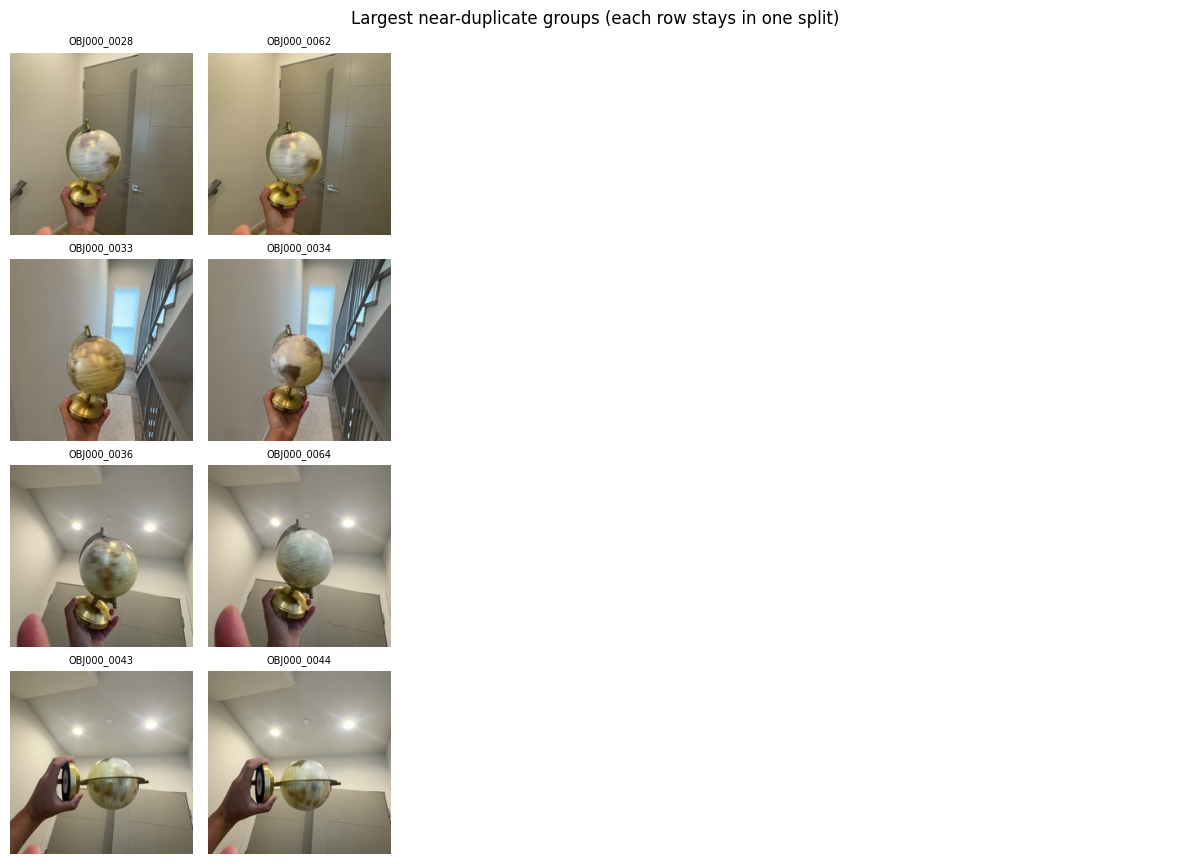

In [11]:
parent = list(range(len(records)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]   # path halving
        x = parent[x]
    return x
same_cls = cls_arr[:, None] == cls_arr[None, :]
md5_arr = np.array([r["md5"] for r in records])
pairs = np.argwhere(same_cls & ((ham <= PHASH_THRESHOLD) | (md5_arr[:, None] == md5_arr[None, :])))
for a, b in pairs:
    if a < b:
        parent[find(a)] = find(b)
groups = {}
for i in range(len(records)):
    groups.setdefault(find(i), []).append(i)
for gid, (root, members) in enumerate(sorted(groups.items(), key=lambda kv: min(kv[1]))):
    for i in members:
        records[i]["group_id"] = f"G{gid:05d}"
        records[i]["group_size"] = len(members)

multi = [m for m in groups.values() if len(m) > 1]
print(f"Near-duplicate grouping: {len(groups)} groups, {len(multi)} with 2+ images, covering {sum(map(len, multi))} images")
for m in groups.values():
    n_cls = int((cls_arr == cls_arr[m[0]]).sum())
    if len(m) > max(10, 0.15 * n_cls):
        issues.append(f"{records[m[0]]['class_id']} has a near-duplicate group of {len(m)} images ({len(m) / n_cls:.0%} of the class); "
                      f"check the examples below and lower PHASH_THRESHOLD if needed")

# Show the largest groups to check by eye that the grouping is reasonable
show = sorted(multi, key=len, reverse=True)[:4]
if show:
    fig, axes = plt.subplots(len(show), 6, figsize=(12, 2.2 * len(show)), squeeze=False)
    for row, m in enumerate(show):
        for col in range(6):
            ax = axes[row][col]; ax.axis("off")
            if col < len(m):
                with Image.open(WORK_DIR / records[m[col]]["local_path"]) as im:
                    ax.imshow(im.convert("RGB"))
                ax.set_title(records[m[col]]["image_id"], fontsize=7)
    plt.suptitle("Largest near-duplicate groups (each row stays in one split)")
    plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "near_duplicate_groups.jpg", dpi=90); plt.show()

## c: stratified 70 / 15 / 15 split by group
Each class is split separately (stratified). Groups are placed largest first, each into the split that is furthest below its target.

In [12]:
SPLITS = ["train", "val", "test"]
for cid in CLASS_IDS:
    idx = CID2IDX[cid]
    cls_groups = [m for m in groups.values() if records[m[0]]["class_id"] == cid]
    rng = np.random.default_rng([SEED, idx])
    order = rng.permutation(len(cls_groups))
    cls_groups = sorted((cls_groups[k] for k in order), key=len, reverse=True)   # largest first; stable sort keeps the random order
    n = sum(map(len, cls_groups))
    targets = [round(n * SPLIT_RATIOS[0]), round(n * SPLIT_RATIOS[1])]
    targets.append(n - sum(targets))
    counts = [0, 0, 0]
    for m in cls_groups:
        k = int(np.argmax([(targets[j] - counts[j]) / max(targets[j], 1) for j in range(3)]))
        counts[k] += len(m)
        for i in m:
            records[i]["split"] = SPLITS[k]

# Per-split availability: 0 images in a split → stop; too few independent groups → warn and review by hand
MIN_GROUPS = dict(train=3, val=3, test=3) if not SMOKE else dict(train=1, val=1, test=1)
empty, few = [], []
for cid in CLASS_IDS:
    for s in SPLITS:
        rs = [r for r in records if r["class_id"] == cid and r["split"] == s]
        n_groups = len({r["group_id"] for r in rs})
        if not rs:
            empty.append(f"{cid}/{s}")
        elif n_groups < MIN_GROUPS[s]:
            few.append(f"{cid}/{s}: {len(rs)} images, {n_groups} groups")
if few:
    issues.append("⚠️ Too few independent groups; review the thumbnails by hand and give the actual group counts in the report: " + "; ".join(few))
    print("⚠️ Too few independent groups:", few)
if empty:
    raise RuntimeError(f"These classes have no images at all in a split, so the class cannot be trained or evaluated: {empty}. "
                       "Check the data first (missing images at import, near-duplicate groups too large); do not move images between splits.")
print("Split availability check passed: every class has images in train / val / test" + ("" if not few else " (some classes have few groups, see above)"))

Split availability check passed: every class has images in train / val / test


Actual split ratios: whole groups are assigned, so they can differ slightly from the 70 / 15 / 15 target.

In [13]:
ratio_rows = []
for cid in CLASS_IDS:
    c = [sum(r["class_id"] == cid and r["split"] == s for r in records) for s in SPLITS]
    ratio_rows.append([cid, *[f"{x / sum(c):.0%}" for x in c]])
tot = [sum(r["split"] == s for r in records) for s in SPLITS]
ratio_rows.append(["**total**", *[f"{x / sum(tot):.1%}" for x in tot]])
ratio_md = md_table(["class", "train", "val", "test"], ratio_rows)
display(Markdown(ratio_md))

| class | train | val | test |
|---|---|---|---|
| OBJ000 | 70% | 15% | 15% |
| OBJ001 | 70% | 15% | 15% |
| OBJ002 | 70% | 15% | 15% |
| OBJ004 | 70% | 15% | 15% |
| OBJ006 | 70% | 15% | 15% |
| OBJ007 | 70% | 15% | 15% |
| OBJ011 | 70% | 15% | 15% |
| OBJ070 | 70% | 15% | 15% |
| OBJ108 | 70% | 15% | 15% |
| OBJ111 | 70% | 15% | 15% |
| OBJ123 | 70% | 15% | 15% |
| OBJ125 | 70% | 15% | 15% |
| OBJ201 | 70% | 15% | 15% |
| OBJ222 | 70% | 15% | 15% |
| OBJ523 | 70% | 15% | 15% |
| OBJ529 | 70% | 15% | 15% |
| OBJ608 | 70% | 15% | 15% |
| OBJ666 | 70% | 15% | 15% |
| OBJ777 | 70% | 15% | 15% |
| OBJ916 | 70% | 15% | 15% |
| **total** | 70.0% | 15.0% | 15.0% |

## d: save `split_manifest.csv` and the data report

In [14]:
MANIFEST_COLS = ["image_id", "class_id", "class_idx", "split", "group_id", "group_size", "md5", "phash",
                 "width", "height", "format", "converted", "src_path", "local_path"]
manifest_path = OUT_DIR / "data" / "split_manifest.csv"
with open(manifest_path, "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=MANIFEST_COLS, extrasaction="ignore")
    w.writeheader(); w.writerows(records)
MANIFEST_SHA = file_hash(manifest_path, "sha256")

split_rows = []
for cid in CLASS_IDS:
    c = [sum(r["class_id"] == cid and r["split"] == s for r in records) for s in SPLITS]
    split_rows.append([cid, *c, sum(c)])
split_rows.append(["**total**", *[sum(r[i] for r in split_rows) for i in range(1, 5)]])
split_md = md_table(["class", "train", "val", "test", "total"], split_rows)
display(Markdown(split_md))
print(f"split_manifest.csv sha256 = {MANIFEST_SHA[:16]}…")
(OUT_DIR / "data" / "data_report.md").write_text(
    "# M1 data report\n\n## Per-class statistics\n\n" + stats_md + "\n\n## Split\n\n" + split_md +
    "\n\n## Actual split ratios (target 70/15/15)\n\n" + ratio_md +
    f"\n\nNear-duplicate threshold: pHash Hamming ≤ {PHASH_THRESHOLD}. Groups: {len(groups)} "
    f"({len(multi)} with ≥2 images).\n\n## Issues\n\n" + "\n".join(f"- {s}" for s in issues) + "\n", encoding="utf-8")

| class | train | val | test | total |
|---|---|---|---|---|
| OBJ000 | 70 | 15 | 15 | 100 |
| OBJ001 | 70 | 15 | 15 | 100 |
| OBJ002 | 70 | 15 | 15 | 100 |
| OBJ004 | 70 | 15 | 15 | 100 |
| OBJ006 | 70 | 15 | 15 | 100 |
| OBJ007 | 70 | 15 | 15 | 100 |
| OBJ011 | 70 | 15 | 15 | 100 |
| OBJ070 | 70 | 15 | 15 | 100 |
| OBJ108 | 70 | 15 | 15 | 100 |
| OBJ111 | 70 | 15 | 15 | 100 |
| OBJ123 | 70 | 15 | 15 | 100 |
| OBJ125 | 70 | 15 | 15 | 100 |
| OBJ201 | 70 | 15 | 15 | 100 |
| OBJ222 | 70 | 15 | 15 | 100 |
| OBJ523 | 70 | 15 | 15 | 100 |
| OBJ529 | 80 | 17 | 17 | 114 |
| OBJ608 | 76 | 16 | 16 | 108 |
| OBJ666 | 70 | 15 | 15 | 100 |
| OBJ777 | 70 | 15 | 15 | 100 |
| OBJ916 | 70 | 15 | 15 | 100 |
| **total** | 1416 | 303 | 303 | 2022 |

split_manifest.csv sha256 = ce9172b7092e48fa…


2898

pHash grouping found 1,983 groups, of which 39 contain 2 images (78 images in total); no group has more than 2 images. The largest groups are consecutive shots of the same scene (e.g., OBJ000_0028 and OBJ000_0062), which suggests that the threshold (Hamming distance ≤ 4) catches real near-duplicates without merging different photos. No near-duplicate pairs were found across classes. The stratified split assigns whole groups, giving 1,416 / 303 / 303 images in train / val / test (70.0% / 15.0% / 15.0%). Every class has 70 / 15 / 15 images, except OBJ529 (80 / 17 / 17) and OBJ608 (76 / 16 / 16), which have more images. Every class has images and enough independent groups in every split, so the availability check passed.

- **No detected near-duplicate group is shared between train, val and test. pHash may still miss near-duplicates (e.g. the same scene from another angle), so this reduces but does not rule out leakage.**

# Task5 - Data pipeline and augmentation
Every image is resized with padding to 224×224 and passed to the model as RGB values in 0–255.

**Why augmentation**: the training set is small (about 70 images per class), so the models can easily memorize it (overfitting). Random flips, rotations, zooms, shifts, brightness/contrast changes and random erasing give the model a slightly different version of each image in every epoch, so it has to learn the object rather than the exact picture. Augmentation is applied to the training set only, so validation and test results stay consistent.

In [15]:
keras.utils.set_random_seed(SEED)

def split_arrays(split):
    rs = [r for r in records if r["split"] == split]
    return [str(WORK_DIR / r["local_path"]) for r in rs], np.array([r["class_idx"] for r in rs]), rs

def decode(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize_with_pad(tf.cast(img, tf.float32), IMG_SIZE, IMG_SIZE)   # keep aspect ratio, pad with black
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8), tf.one_hot(label, NUM_CLASSES)

augment = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(15 / 360, fill_mode="reflect", seed=SEED),                # ±15°
    layers.RandomZoom(height_factor=(-0.2, 0.0), fill_mode="reflect", seed=SEED),   # zoom in up to 20% ≈ random crop
    layers.RandomTranslation(0.1, 0.1, fill_mode="reflect", seed=SEED),
    layers.RandomContrast(0.2, seed=SEED),
    layers.RandomBrightness(0.2, value_range=(0, 255), seed=SEED),
], name="augment")

def random_erase(img, p=0.5):
    """Random erasing: with probability p, cover a rectangle (10%–35% of the side) with noise to simulate occlusion."""
    def erase():
        eh = tf.random.uniform([], int(0.10 * IMG_SIZE), int(0.35 * IMG_SIZE), dtype=tf.int32)
        ew = tf.random.uniform([], int(0.10 * IMG_SIZE), int(0.35 * IMG_SIZE), dtype=tf.int32)
        y = tf.random.uniform([], 0, IMG_SIZE - eh, dtype=tf.int32)
        x = tf.random.uniform([], 0, IMG_SIZE - ew, dtype=tf.int32)
        mask = tf.pad(tf.ones([eh, ew, 1]), [[y, IMG_SIZE - y - eh], [x, IMG_SIZE - x - ew], [0, 0]])
        return img * (1 - mask) + tf.random.uniform([IMG_SIZE, IMG_SIZE, 3], 0, 255) * mask
    return tf.cond(tf.random.uniform([]) < p, erase, lambda: img)

def make_ds(split, training):
    paths, labels, _ = split_arrays(split)
    # decoded uint8 images are cached in memory, so files are read only once
    ds = tf.data.Dataset.from_tensor_slices((paths, labels)).map(decode, num_parallel_calls=tf.data.AUTOTUNE).cache()
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda x, y: (random_erase(x), y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.batch(BATCH).map(lambda x, y: (tf.clip_by_value(augment(x, training=True), 0, 255), y),
                                 num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.batch(BATCH)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds("train", True), make_ds("val", False), make_ds("test", False)
N_TRAIN = len(split_arrays("train")[0])
STEPS_PER_EPOCH = math.ceil(N_TRAIN / BATCH)
print(f"train / val / test images: {N_TRAIN} / {len(split_arrays('val')[0])} / {len(split_arrays('test')[0])}, steps per epoch = {STEPS_PER_EPOCH}")

train / val / test images: 1416 / 303 / 303, steps per epoch = 45


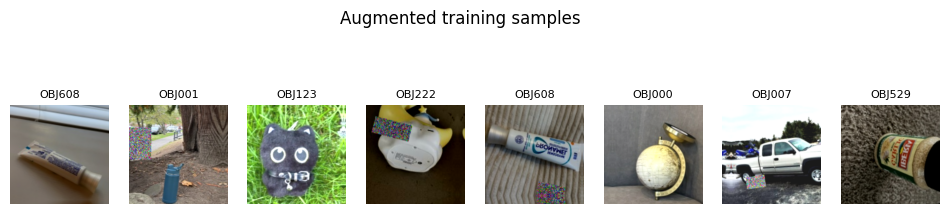

In [16]:
# Look at some augmented training images
xb, yb = next(iter(train_ds))
plt.figure(figsize=(12, 3))
for k in range(min(8, len(xb))):
    plt.subplot(1, 8, k + 1); plt.imshow(xb[k].numpy().astype("uint8")); plt.axis("off")
    plt.title(CLASSES[int(np.argmax(yb[k]))], fontsize=8)
plt.suptitle("Augmented training samples"); plt.show()

The pipeline loads 1,416 / 303 / 303 images for train / val / test (45 steps per epoch). In the augmented samples the objects are still clearly recognizable and the labels match the images; about half of the images show a random-erasing patch, as expected with p = 0.5.

# Task6 - Four models

## a: custom CNN (trained from scratch, baseline)

In [17]:
def build_custom_cnn():
    """Baseline from scratch: 4 conv blocks (Conv-BN-ReLU x2 + MaxPool), then GAP + Dropout + Dense."""
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1 / 255.0)(inp)                 # 0–255 → 0–1
    for filters in [32, 64, 128, 256]:
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)   # no bias: BatchNorm has its own shift
            x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(inp, layers.Dense(NUM_CLASSES, activation="softmax")(x), name="custom_cnn"), None

## b: pretrained models: MobileNetV2, ResNet-50, EfficientNet-B0
Transfer learning as in the lecture: `include_top=False` + `pooling="avg"`, frozen backbone, new 20-class head. Each model has its own preprocessing, built in as the first layer, so the saved model always carries the right preprocessing.

In [18]:
@keras.saving.register_keras_serializable(package="m1")
class CaffePreprocess(layers.Layer):
    """ResNet-50 caffe-style preprocessing: RGB → BGR, then subtract the ImageNet means (no scaling)."""
    def call(self, x):
        x = keras.ops.flip(x, axis=-1)
        return x - keras.ops.convert_to_tensor([103.939, 116.779, 123.68], dtype=x.dtype)

# EfficientNet has its preprocessing built in, so it takes 0–255 directly (pre=None)
PRETRAINED_SPECS = {
    "mobilenetv2":    dict(ctor=keras.applications.MobileNetV2,    pre=lambda: layers.Rescaling(1 / 127.5, offset=-1), unfreeze_from="block_13_expand"),
    "resnet50":       dict(ctor=keras.applications.ResNet50,       pre=lambda: CaffePreprocess(),                      unfreeze_from="conv5_"),
    "efficientnetb0": dict(ctor=keras.applications.EfficientNetB0, pre=None,                                           unfreeze_from="block6"),
}

def build_pretrained(name):
    spec = PRETRAINED_SPECS[name]
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = spec["pre"]()(inp) if spec["pre"] else inp
    base = spec["ctor"](include_top=False, weights=PRETRAINED, input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    base.trainable = False
    x = base(x, training=False)          # BatchNorm always in inference mode; its statistics stay fixed after unfreezing too
    x = layers.Dropout(0.3)(x)
    return keras.Model(inp, layers.Dense(NUM_CLASSES, activation="softmax")(x), name=name), base

def unfreeze_top(base, prefix):
    """Unfreeze the top blocks, starting at the first layer whose name starts with prefix; BatchNorm layers stay frozen."""
    base.trainable = True
    start = next(i for i, l in enumerate(base.layers) if l.name.startswith(prefix))
    for i, l in enumerate(base.layers):
        l.trainable = i >= start and not isinstance(l, layers.BatchNormalization)

## c: compile settings and model sizes

In [19]:
def compile_model(model, lr, epochs):
    # AdamW + cosine decay of the learning rate over the whole stage
    sched = keras.optimizers.schedules.CosineDecay(lr, decay_steps=max(1, epochs * STEPS_PER_EPOCH))
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=sched, weight_decay=WEIGHT_DECAY),
                  loss="categorical_crossentropy",
                  metrics=["accuracy", keras.metrics.F1Score(average="macro", name="f1")])

def count_params(model):
    trainable = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    return int(model.count_params()), trainable

for name in MODEL_NAMES:
    m, _ = build_custom_cnn() if name == "custom_cnn" else build_pretrained(name)
    print(f"{name:15s} total params = {m.count_params():,}")
    del m
keras.backend.clear_session()

custom_cnn      total params = 1,180,276
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
mobilenetv2     total params = 2,283,604
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
resnet50        total params = 23,628,692
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
efficientnetb0  total params = 4,075,191


The four models differ in their core building block, so they count as distinct architectures:
- **custom CNN**: plain stacked 3×3 convolutions, trained from scratch (baseline).
- **MobileNetV2**: depthwise-separable inverted residual blocks; lightweight.
- **ResNet-50**: bottleneck residual blocks; standard large backbone.
- **EfficientNet-B0**: compound-scaled MBConv blocks with squeeze-and-excitation.

Hyperparameter variants of one architecture (learning rate, epochs, freezing schedule) are reported under that architecture and are not extra models.

# Task7 - Training
Custom CNN: one stage from scratch. Pretrained models: stage 1 trains only the head (frozen backbone); stage 2 unfreezes the top blocks with a 10× lower learning rate. Early stopping on validation accuracy (the same metric used for model selection) keeps the best epoch. If fine-tuning achieves lower validation accuracy than stage 1, the stage-1 weights are restored (on a tie, the fine-tuned weights are kept).

In [20]:
def fit(model, epochs, patience):
    cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=patience, restore_best_weights=True)]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cb, verbose=2).history

def predict(model, ds):
    probs = model.predict(ds, verbose=0)
    y = np.concatenate([np.argmax(yb, 1) for _, yb in ds])
    return y, probs

def metrics_from(y, pred, k):
    # confusion matrix: rows = true class, columns = predicted class
    cm = np.zeros((k, k), dtype=int)
    np.add.at(cm, (y, pred), 1)
    tp = np.diag(cm).astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        prec = np.nan_to_num(tp / cm.sum(0)); rec = np.nan_to_num(tp / cm.sum(1))
        f1 = np.nan_to_num(2 * prec * rec / (prec + rec))
    return dict(accuracy=float(tp.sum() / cm.sum()), macro_f1=float(f1.mean()), per_class_f1=f1.tolist(), confusion=cm.tolist())

In [21]:
results, histories = {}, {}
for name in MODEL_NAMES:
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)    # same seed for every model
    print(f"\n========== {name} ==========")
    t0 = time.time()
    if name == "custom_cnn":
        model, base = build_custom_cnn()
        compile_model(model, LR["cnn"], EPOCHS["cnn"])
        h = fit(model, EPOCHS["cnn"], PATIENCE["cnn"])
        stages = [("scratch", h)]
        chosen_stage = "scratch"
    else:
        model, base = build_pretrained(name)
        compile_model(model, LR["head"], EPOCHS["head"])
        h1 = fit(model, EPOCHS["head"], EPOCHS["head"])             # stage 1: head only
        best1 = max(h1["val_accuracy"])
        stage1_w = OUT_DIR / "models" / f"{name}_stage1.weights.h5"
        model.save_weights(stage1_w)
        unfreeze_top(base, PRETRAINED_SPECS[name]["unfreeze_from"])
        compile_model(model, LR["finetune"], EPOCHS["finetune"])
        h2 = fit(model, EPOCHS["finetune"], PATIENCE["finetune"])   # stage 2: fine-tune the top blocks
        stages = [("head", h1), ("finetune", h2)]
        chosen_stage = "finetune"
        if max(h2["val_accuracy"]) < best1:                                # fine-tuning is worse than stage 1 → back to stage 1
            model.load_weights(stage1_w)
            chosen_stage = "head"
        stage1_w.unlink()
    train_min = (time.time() - t0) / 60
    model_path = OUT_DIR / "models" / f"{name}.keras"
    model.save(model_path)
    y_val, p_val = predict(model, val_ds)
    total, trainable = count_params(model)
    results[name] = dict(model=name, val=metrics_from(y_val, p_val.argmax(1), NUM_CLASSES), params_total=total,
                         params_trainable_final=trainable, train_minutes=round(train_min, 2), chosen_stage=chosen_stage,
                         epochs_run={s: len(hh["loss"]) for s, hh in stages}, model_path=str(model_path),
                         model_sha256=file_hash(model_path, "sha256"))
    histories[name] = stages
    print(f"{name}: val accuracy = {results[name]['val']['accuracy']:.4f}, val macro-F1 = {results[name]['val']['macro_f1']:.4f}, time {train_min:.1f} min, stage used = {chosen_stage}")


========== custom_cnn ==========
Epoch 1/60
45/45 - 73s - 2s/step - accuracy: 0.1631 - f1: 0.1484 - loss: 2.7830 - val_accuracy: 0.0495 - val_f1: 0.0047 - val_loss: 3.5713
Epoch 2/60
45/45 - 21s - 474ms/step - accuracy: 0.2881 - f1: 0.2677 - loss: 2.3052 - val_accuracy: 0.0792 - val_f1: 0.0347 - val_loss: 3.8146
Epoch 3/60
45/45 - 21s - 459ms/step - accuracy: 0.3446 - f1: 0.3292 - loss: 2.1096 - val_accuracy: 0.0627 - val_f1: 0.0229 - val_loss: 3.6663
Epoch 4/60
45/45 - 20s - 451ms/step - accuracy: 0.4188 - f1: 0.4065 - loss: 1.8558 - val_accuracy: 0.0594 - val_f1: 0.0122 - val_loss: 4.8785
Epoch 5/60
45/45 - 21s - 465ms/step - accuracy: 0.4852 - f1: 0.4757 - loss: 1.7157 - val_accuracy: 0.1221 - val_f1: 0.0599 - val_loss: 3.8805
Epoch 6/60
45/45 - 21s - 458ms/step - accuracy: 0.5092 - f1: 0.5027 - loss: 1.5968 - val_accuracy: 0.0858 - val_f1: 0.0429 - val_loss: 4.8714
Epoch 7/60
45/45 - 21s - 467ms/step - accuracy: 0.5516 - f1: 0.5404 - loss: 1.5015 - val_accuracy: 0.1188 - val_f1: 0

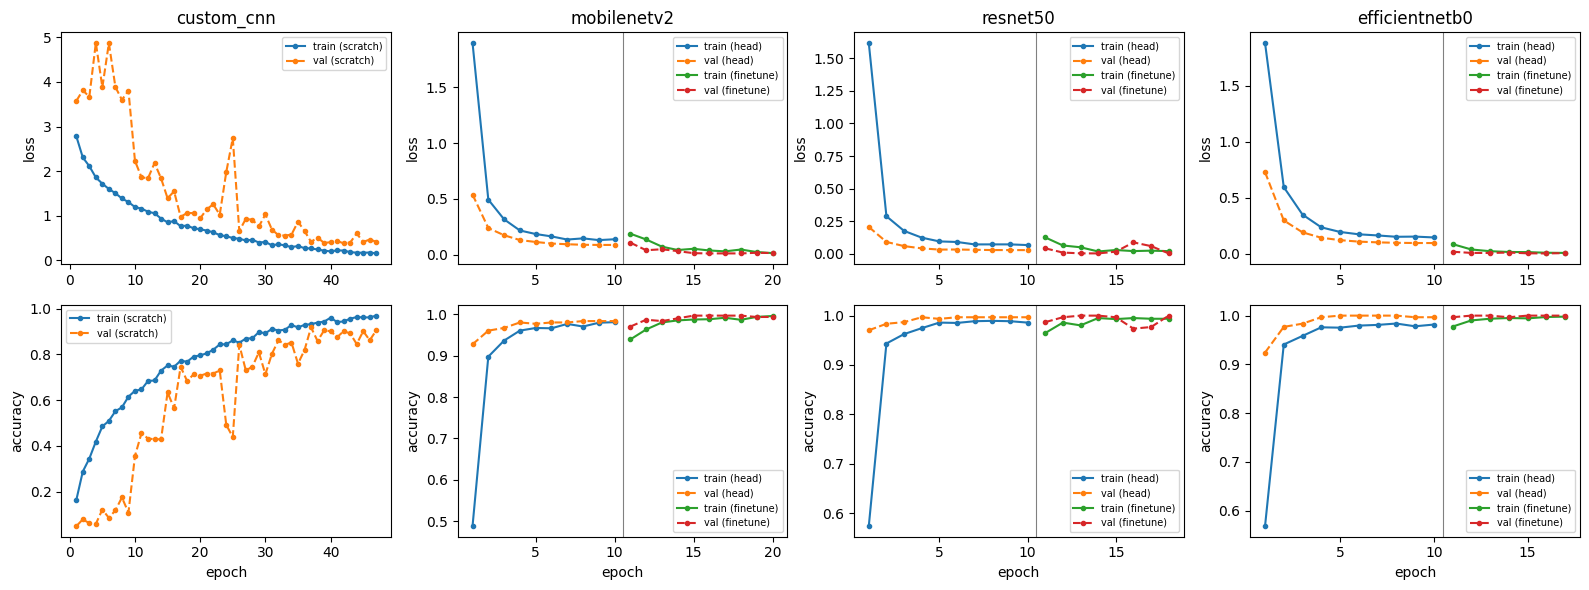

In [22]:
# Training curves (gray line = start of fine-tuning)
fig, axes = plt.subplots(2, len(MODEL_NAMES), figsize=(4 * len(MODEL_NAMES), 6), squeeze=False)
for col, name in enumerate(MODEL_NAMES):
    offset = 0
    for stage, hh in histories[name]:
        ep = np.arange(offset, offset + len(hh["loss"])) + 1
        axes[0][col].plot(ep, hh["loss"], "o-", ms=3, label=f"train ({stage})"); axes[0][col].plot(ep, hh["val_loss"], "o--", ms=3, label=f"val ({stage})")
        axes[1][col].plot(ep, hh["accuracy"], "o-", ms=3, label=f"train ({stage})"); axes[1][col].plot(ep, hh["val_accuracy"], "o--", ms=3, label=f"val ({stage})")
        offset += len(hh["loss"])
        if offset and stage == "head":
            for r in (0, 1): axes[r][col].axvline(offset + 0.5, color="gray", lw=0.8)
    axes[0][col].set_title(name); axes[0][col].set_ylabel("loss"); axes[1][col].set_ylabel("accuracy"); axes[1][col].set_xlabel("epoch")
    axes[0][col].legend(fontsize=7); axes[1][col].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "training_curves.png", dpi=120); plt.show()

The custom CNN trained from scratch needed 47 epochs (early stopping; best at epoch 37) and reached a val accuracy of 0.9175 after 18 minutes. Its validation curve is very unstable (e.g., 0.73 → 0.44 → 0.84 between epochs 23 and 26), and in the first 9 epochs val accuracy stayed near chance (5–17%) while train accuracy was already 16–62%, likely because the BatchNorm statistics had not settled yet. The three pretrained models were far better: after only the head stage they reached 0.9835 (MobileNetV2), 0.9967 (ResNet-50) and 1.0000 (EfficientNet-B0), and fine-tuning raised them to 0.9967, 1.0000 and 1.0000 in about 7 minutes each. During the head stage train accuracy is below val accuracy because it is measured with augmentation and dropout on.

**Transfer learning clearly helps on this small dataset: every pretrained model beats the custom CNN by about 8 percentage points and trains in less than half the time. The three pretrained models are almost perfect on validation, so validation alone can barely separate them (one image = 0.33 points).**

# Task8 - Select the best model on validation only
Rule (fixed in advance, same as Assignment 1 except for the CI formula):

1. The top model has the highest **validation accuracy**; its 95% CI is computed with the **Wilson interval**. Assignment 1 used the normal approximation acc ± 1.96·√(acc·(1−acc)/n), but that interval has zero width when acc = 1.0, which happens here (two models reach 100% on validation).
2. Every model whose validation accuracy is at or above that CI's lower bound counts as competitive (with ~300 validation images, a 1–2 point difference is not strong evidence that one model is better).
3. Among the competitive models, the one with the **fewest parameters** wins; ties go to the **shortest training time** (as in Assignment 1; all four models train on the same Colab T4, so the times are comparable).

Precondition: classes are roughly balanced in validation (checked below). Macro-F1 and per-class F1 are still computed and reported, to show whether any class is much worse. The decision is saved to `selection.json` **before** any model is evaluated on test.

In [23]:
# Record the hardware: training time depends on the machine (Assignment 1 Task 4 also compared training time)
CPU_INFO = platform.processor() or platform.machine()
if Path("/proc/cpuinfo").exists():
    for line in Path("/proc/cpuinfo").read_text().splitlines():
        if line.startswith("model name"):
            CPU_INFO = line.split(":", 1)[1].strip(); break
GPUS = tf.config.list_physical_devices("GPU")
GPU_INFO = tf.config.experimental.get_device_details(GPUS[0]).get("device_name", "GPU") if GPUS else "none"
print(f"Training hardware: GPU = {GPU_INFO}, CPU = {CPU_INFO}")
for name in MODEL_NAMES:
    print(f"{name:15s} training time {results[name]['train_minutes']:.1f} min, params {results[name]['params_total'] / 1e6:.2f} M")

Training hardware: GPU = Tesla T4, CPU = Intel(R) Xeon(R) CPU @ 2.00GHz
custom_cnn      training time 18.0 min, params 1.18 M
mobilenetv2     training time 7.2 min, params 2.28 M
resnet50        training time 7.1 min, params 23.63 M
efficientnetb0  training time 7.4 min, params 4.08 M


In [28]:
# Assignment 1 rule: models within the 95% CI of the best are competitive; then fewest parameters, then shortest training time.
# The CI uses the Wilson interval instead of acc ± 1.96·SE, because the latter has zero width when acc = 1.0.
def acc_ci(acc, n, z=1.96):
    """Wilson 95% CI of accuracy. Unlike acc ± 1.96·SE, it does not collapse to zero width when acc = 1."""
    center = (acc + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(acc * (1 - acc) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(0.0, center - half), min(1.0, center + half)

# Precondition: selecting by accuracy assumes the classes are roughly balanced in validation
val_counts = [sum(r["class_id"] == cid and r["split"] == "val" for r in records) for cid in CLASS_IDS]
print(f"Validation images per class: min {min(val_counts)}, max {max(val_counts)}")
if min(val_counts) == 0 or max(val_counts) / min(val_counts) > 1.5:
    issues.append(f"⚠️ validation classes are unbalanced ({min(val_counts)}–{max(val_counts)}); state this in the report and check macro-F1 too")
    print(issues[-1])

N_VAL = len(split_arrays("val")[0])
for name in MODEL_NAMES:
    results[name]["val_ci"] = acc_ci(results[name]["val"]["accuracy"], N_VAL)

ranked = sorted(MODEL_NAMES, key=lambda n: results[n]["val"]["accuracy"], reverse=True)
top = ranked[0]
threshold = results[top]["val_ci"][0]            # lower bound of the top model's 95% CI
competitive = [n for n in ranked if results[n]["val"]["accuracy"] >= threshold]
best = min(competitive, key=lambda n: (results[n]["params_total"], results[n]["train_minutes"]))
reason = (f"{top} has the highest validation accuracy ({results[top]['val']['accuracy']:.4f}, 95% CI "
          f"[{results[top]['val_ci'][0]:.4f}, {results[top]['val_ci'][1]:.4f}], n={N_VAL}); models within this CI: {competitive}; "
          f"chose the one with the fewest parameters" + (" (the top model itself)" if best == top else ""))
selection = dict(rule="Assignment 1 rule: models whose val accuracy is within the 95% Wilson CI of the best are competitive; "
                      "among them choose the fewest parameters, then the shortest training time",
                 best=best, reason=reason, n_val=N_VAL, gpu=GPU_INFO, ci_threshold=round(threshold, 4), competitive=competitive,
                 val_class_counts=dict(min=min(val_counts), max=max(val_counts)),
                 val_ranking=[dict(model=n, val_accuracy=round(results[n]["val"]["accuracy"], 4),
                                   val_ci=[round(x, 4) for x in results[n]["val_ci"]],
                                   val_macro_f1=round(results[n]["val"]["macro_f1"], 4), params=results[n]["params_total"],
                                                                      train_minutes=results[n]["train_minutes"]) for n in ranked],
                 decided_at=datetime.now(timezone.utc).isoformat(), test_seen_before_decision=False)
(OUT_DIR / "records" / "selection.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
print("Selection rule:", selection["rule"])
for row in selection["val_ranking"]:
    print("  ", row)
print(f"Competitive (val accuracy >= {threshold:.4f}, the top model's CI lower bound): {competitive}")
print(f"Best model: {best}")

Validation images per class: min 15, max 17
Selection rule: Assignment 1 rule: models whose val accuracy is within the 95% Wilson CI of the best are competitive; among them choose the fewest parameters, then the shortest training time
   {'model': 'resnet50', 'val_accuracy': 1.0, 'val_ci': [0.9875, 1.0], 'val_macro_f1': 1.0, 'params': 23628692, 'train_minutes': 7.11}
   {'model': 'efficientnetb0', 'val_accuracy': 1.0, 'val_ci': [0.9875, 1.0], 'val_macro_f1': 1.0, 'params': 4075191, 'train_minutes': 7.44}
   {'model': 'mobilenetv2', 'val_accuracy': 0.9967, 'val_ci': [0.9815, 0.9994], 'val_macro_f1': 0.9968, 'params': 2283604, 'train_minutes': 7.25}
   {'model': 'custom_cnn', 'val_accuracy': 0.9175, 'val_ci': [0.881, 0.9435], 'val_macro_f1': 0.9164, 'params': 1180276, 'train_minutes': 17.97}
Competitive (val accuracy >= 0.9875, the top model's CI lower bound): ['resnet50', 'efficientnetb0', 'mobilenetv2']
Best model: mobilenetv2


On validation (n = 303, 15–17 images per class), ResNet-50 and EfficientNet-B0 both reach 100% accuracy (95% Wilson CI [0.9875, 1.0]), MobileNetV2 reaches 0.9967 (one image wrong) and the custom CNN 0.9175 (CI [0.881, 0.9435]). MobileNetV2 is above the top model’s CI lower bound (0.9875), so the three pretrained models are competitive: their difference is at most one validation image, which is not strong evidence that one model is better. The custom CNN’s CI upper bound (0.9435) is well below 0.9875, so it is clearly worse. Among the competitive models, MobileNetV2 has the fewest parameters (2.28 M vs 4.08 M for EfficientNet-B0 and 23.63 M for ResNet-50), so it is selected.

- **Best model (chosen on validation, before looking at test): MobileNetV2.**

# Task9 - Evaluate all models on test
Only after the choice is fixed. The test set is never used to choose.

## a: test predictions

In [29]:
test_preds = {}
for name in MODEL_NAMES:
    model = keras.models.load_model(results[name]["model_path"])
    y_test, p_test = predict(model, test_ds)
    test_preds[name] = (y_test, p_test)
    results[name]["test"] = metrics_from(y_test, p_test.argmax(1), NUM_CLASSES)
# every test evaluation is logged
with open(OUT_DIR / "records" / "test_run_log.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(dict(time=datetime.now(timezone.utc).isoformat(), models=MODEL_NAMES, selected=best,
                            reason="M1 report: evaluate all candidates after the validation-based selection")) + "\n")

## b: model comparison table (best model in bold)

In [37]:
cmp_rows = []
for name in ranked:
    r = results[name]
    test_ci = acc_ci(r["test"]["accuracy"], len(test_preds[name][0]))   # Wilson 95% CI on the test set
    cmp_rows.append([("**" + name + "**") if name == best else name, f"{r['params_total'] / 1e6:.2f} M",
                     f"{r['val']['accuracy']:.4f}", f"{r['val_ci'][0]:.3f}–{r['val_ci'][1]:.3f}", f"{r['val']['macro_f1']:.4f}",
                     f"{r['test']['accuracy']:.4f}", f"{test_ci[0]:.3f}–{test_ci[1]:.3f}", f"{r['test']['macro_f1']:.4f}",
                     f"{r['train_minutes']:.1f}", r["chosen_stage"]])
cmp_md = md_table(["model", "params", "val acc", "val acc 95% CI", "val macro-F1", "test acc", "test acc 95% CI", "test macro-F1", "train min", "stage used"], cmp_rows)
display(Markdown(cmp_md))
print(f"All training times measured on {GPU_INFO}")

| model | params | val acc | val acc 95% CI | val macro-F1 | test acc | test acc 95% CI | test macro-F1 | train min | stage used |
|---|---|---|---|---|---|---|---|---|---|
| resnet50 | 23.63 M | 1.0000 | 0.987–1.000 | 1.0000 | 0.9967 | 0.982–0.999 | 0.9967 | 7.1 | finetune |
| efficientnetb0 | 4.08 M | 1.0000 | 0.987–1.000 | 1.0000 | 1.0000 | 0.987–1.000 | 1.0000 | 7.4 | finetune |
| **mobilenetv2** | 2.28 M | 0.9967 | 0.982–0.999 | 0.9968 | 0.9934 | 0.976–0.998 | 0.9933 | 7.2 | finetune |
| custom_cnn | 1.18 M | 0.9175 | 0.881–0.943 | 0.9164 | 0.8911 | 0.851–0.921 | 0.8899 | 18.0 | scratch |

All training times measured on Tesla T4


## c: per-class test F1

In [39]:
pc_rows = [[CLASSES[k], *[f"{results[n]['test']['per_class_f1'][k]:.3f}" for n in MODEL_NAMES]] for k in range(NUM_CLASSES)]
pc_md = md_table(["class", *MODEL_NAMES], pc_rows)
display(Markdown(pc_md))

| class | custom_cnn | mobilenetv2 | resnet50 | efficientnetb0 |
|---|---|---|---|---|
| OBJ000 | 0.839 | 1.000 | 1.000 | 1.000 |
| OBJ001 | 0.857 | 1.000 | 1.000 | 1.000 |
| OBJ002 | 0.867 | 1.000 | 1.000 | 1.000 |
| OBJ004 | 0.938 | 0.966 | 0.966 | 1.000 |
| OBJ006 | 0.815 | 1.000 | 1.000 | 1.000 |
| OBJ007 | 0.857 | 0.968 | 0.968 | 1.000 |
| OBJ011 | 0.750 | 1.000 | 1.000 | 1.000 |
| OBJ070 | 0.933 | 1.000 | 1.000 | 1.000 |
| OBJ108 | 0.933 | 1.000 | 1.000 | 1.000 |
| OBJ111 | 0.828 | 1.000 | 1.000 | 1.000 |
| OBJ123 | 0.966 | 0.966 | 1.000 | 1.000 |
| OBJ125 | 0.846 | 1.000 | 1.000 | 1.000 |
| OBJ201 | 0.938 | 1.000 | 1.000 | 1.000 |
| OBJ222 | 0.929 | 1.000 | 1.000 | 1.000 |
| OBJ523 | 0.933 | 1.000 | 1.000 | 1.000 |
| OBJ529 | 0.970 | 1.000 | 1.000 | 1.000 |
| OBJ608 | 0.857 | 1.000 | 1.000 | 1.000 |
| OBJ666 | 0.966 | 1.000 | 1.000 | 1.000 |
| OBJ777 | 0.812 | 0.968 | 1.000 | 1.000 |
| OBJ916 | 0.966 | 1.000 | 1.000 | 1.000 |

## d: confusion matrices (all models)

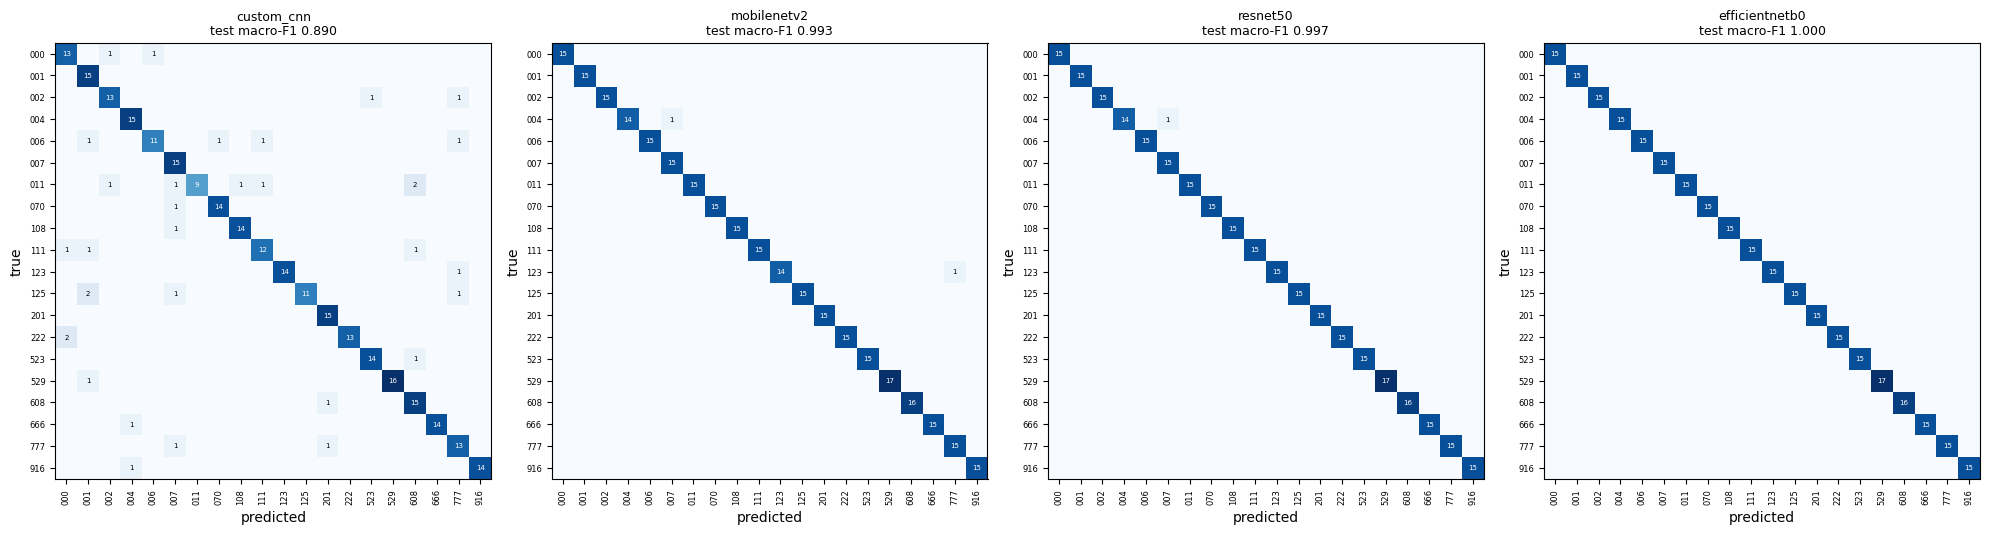

In [40]:
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(5 * len(MODEL_NAMES), 5), squeeze=False)
for col, name in enumerate(MODEL_NAMES):
    cm = np.array(results[name]["test"]["confusion"])
    ax = axes[0][col]; ax.imshow(cm, cmap="Blues")
    ax.set_title(f"{name}\ntest macro-F1 {results[name]['test']['macro_f1']:.3f}", fontsize=9)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels([CLASSES[k][3:] for k in range(NUM_CLASSES)], rotation=90, fontsize=6)   # "OBJ011" → "011"
    ax.set_yticklabels([CLASSES[k][3:] for k in range(NUM_CLASSES)], fontsize=6)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=5, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "confusion_matrices.png", dpi=150); plt.show()

## e: where the best model fails

mobilenetv2: most-confused class pairs (true → predicted : images)
  OBJ123 → OBJ777 : 1
  OBJ004 → OBJ007 : 1


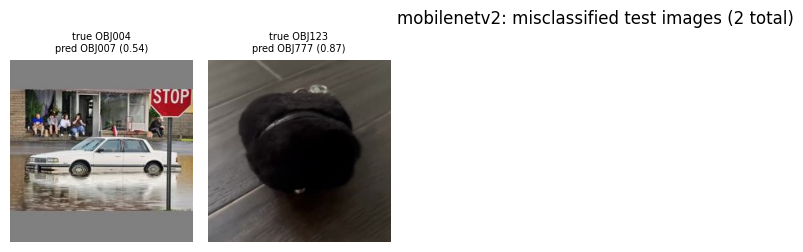

In [41]:
# Most-confused class pairs (off-diagonal cells of the confusion matrix)
cm = np.array(results[best]["test"]["confusion"])
off = [(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j]]
off.sort(reverse=True)
print(f"{best}: most-confused class pairs (true → predicted : images)")
for c, a, b in off[:5]:
    print(f"  {a} → {b} : {c}")

# Misclassified test images
y_test, p_test = test_preds[best]
_, _, test_rows = split_arrays("test")
wrong = np.where(p_test.argmax(1) != y_test)[0]
if len(wrong):
    k = min(12, len(wrong))
    plt.figure(figsize=(12, 2.6 * math.ceil(k / 6)))
    for n, i in enumerate(wrong[:k]):
        plt.subplot(math.ceil(k / 6), 6, n + 1)
        with Image.open(WORK_DIR / test_rows[i]["local_path"]) as im:
            plt.imshow(im.convert("RGB"))
        plt.axis("off")
        plt.title(f"true {CLASSES[y_test[i]]}\npred {CLASSES[int(p_test[i].argmax())]} ({p_test[i].max():.2f})", fontsize=7)
    plt.suptitle(f"{best}: misclassified test images ({len(wrong)} total)")
    plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / f"misclassified_{best}.png", dpi=120); plt.show()
else:
    print(f"{best} has no misclassified test images.")

## f: justification points for the report (best model vs runner-up)

In [42]:
runner = ranked[1] if ranked[0] == best else ranked[0]
b, r2 = results[best], results[runner]
justification = (
    f"Best model: {best}. Selection rule: {selection['rule']}; decided on validation before test evaluation.\n"
    f"- Validation accuracy: {best} {b['val']['accuracy']:.4f} (95% CI {b['val_ci'][0]:.4f}–{b['val_ci'][1]:.4f}, n={N_VAL}) vs runner-up {runner} {r2['val']['accuracy']:.4f}; "
    f"competitive within the top model's CI: {selection['competitive']}; chosen by fewest parameters, then training time. "
    f"Validation macro-F1: {b['val']['macro_f1']:.4f} vs {r2['val']['macro_f1']:.4f}.\n"
    f"- Test macro-F1: {b['test']['macro_f1']:.4f} vs {r2['test']['macro_f1']:.4f}; test accuracy {b['test']['accuracy']:.4f} vs {r2['test']['accuracy']:.4f}.\n"
    f"- Size: {b['params_total'] / 1e6:.2f} M vs {r2['params_total'] / 1e6:.2f} M params; training time {b['train_minutes']:.1f} vs {r2['train_minutes']:.1f} min ({GPU_INFO}).\n"
    f"- From-scratch baseline custom_cnn test macro-F1: {results['custom_cnn']['test']['macro_f1']:.4f} (value of transfer learning).\n"
    f"- Most-confused pairs for {best}: " + ("; ".join(f"{a}→{b_} ({c})" for c, a, b_ in off[:3]) or "none") + ".\n")
print(justification)

Best model: mobilenetv2. Selection rule: Assignment 1 rule: models whose val accuracy is within the 95% Wilson CI of the best are competitive; among them choose the fewest parameters, then the shortest training time; decided on validation before test evaluation.
- Validation accuracy: mobilenetv2 0.9967 (95% CI 0.9815–0.9994, n=303) vs runner-up resnet50 1.0000; competitive within the top model's CI: ['resnet50', 'efficientnetb0', 'mobilenetv2']; chosen by fewest parameters, then training time. Validation macro-F1: 0.9968 vs 1.0000.
- Test macro-F1: 0.9933 vs 0.9967; test accuracy 0.9934 vs 0.9967.
- Size: 2.28 M vs 23.63 M params; training time 7.2 vs 7.1 min (Tesla T4).
- From-scratch baseline custom_cnn test macro-F1: 0.8899 (value of transfer learning).
- Most-confused pairs for mobilenetv2: OBJ123→OBJ777 (1); OBJ004→OBJ007 (1).



On test, EfficientNet-B0 reaches 1.0000, ResNet-50 0.9967 (1 error) and MobileNetV2 0.9934 (2 errors), i.e. 0, 1 and 2 test errors, respectively. MobileNetV2 remains the selected model under the validation-based selection rule. The custom CNN reaches only 0.8911, clearly below all pretrained models. MobileNetV2’s two errors are a stop sign where a car fills most of the image (predicted as the pickup truck) and a black plush toy seen from the back (predicted as the black bottle).

**On test, the three pretrained models made 0, 1 and 2 errors and all clearly beat the custom CNN; MobileNetV2 remains the selected model.**

# Task10 - Run records
One JSON record per model (config, seed, data checksums, code commit, metrics, model file), plus `results.csv` and `M1_results_for_report.md`. They are imported into MLflow later with the same run IDs.

In [43]:
def git_info():
    if REPO_DIR is None:
        return "not recorded", None
    try:
        commit = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
        dirty = bool(subprocess.run(["git", "-C", str(REPO_DIR), "status", "--porcelain"], capture_output=True, text=True, check=True).stdout.strip())
        return commit, dirty
    except Exception:
        return "not recorded", None

commit, dirty = git_info()
gpu = [tf.config.experimental.get_device_details(g).get("device_name", "GPU") for g in tf.config.list_physical_devices("GPU")]
env = dict(python=platform.python_version(), tensorflow=tf.__version__, keras=keras.__version__, numpy=np.__version__,
           platform=platform.platform(), gpu=gpu or ["none"], cpu=CPU_INFO, colab=IN_COLAB)
config = dict(seed=SEED, split_ratios=SPLIT_RATIOS, img_size=IMG_SIZE, batch=BATCH, phash_threshold=PHASH_THRESHOLD,
              epochs=EPOCHS, patience=PATIENCE, lr=LR, weight_decay=WEIGHT_DECAY, optimizer="AdamW + CosineDecay",
              augmentation=["flip_h", "rotate±15°", "zoom_in≤20%", "translate±10%", "contrast±20%", "brightness±20%", "random_erase p=0.5"],
              pretrained_weights=PRETRAINED, smoke=SMOKE, max_per_class=MAX_PER_CLASS)
for name in MODEL_NAMES:
    r = results[name]
    rec = dict(run_id=uuid.uuid4().hex, run_tag=RUN_TAG, task="M1 single-object classification", model=name,
               git_commit=commit, git_dirty=dirty, config=config,
               data=dict(split_manifest_sha256=MANIFEST_SHA, classes_json_sha256=CLASSES_SHA, n_images=len(records),
                         n_per_split={s: sum(x["split"] == s for x in records) for s in SPLITS}),
               selection_rule=selection["rule"], chosen_stage=r["chosen_stage"], epochs_run=r["epochs_run"],
               params_total=r["params_total"], params_trainable_final=r["params_trainable_final"],
               validation_metrics=dict(accuracy=r["val"]["accuracy"], macro_f1=r["val"]["macro_f1"]),
               final_test_metrics=dict(accuracy=r["test"]["accuracy"], macro_f1=r["test"]["macro_f1"],
                                       per_class_f1=dict(zip(CLASS_IDS, r["test"]["per_class_f1"]))),
               train_minutes=r["train_minutes"], environment=env,
               artifact=dict(path=f"models/{name}.keras", sha256=r["model_sha256"]), selected_as_best=(name == best))
    (OUT_DIR / "records" / f"run_{name}.json").write_text(json.dumps(rec, indent=2), encoding="utf-8")

In [44]:
with open(OUT_DIR / "records" / "results.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["model", "params_total", "val_macro_f1", "val_accuracy", "test_accuracy", "test_macro_f1", "train_minutes", "chosen_stage", "selected"])
    for name in ranked:
        r = results[name]
        w.writerow([name, r["params_total"], r["val"]["macro_f1"], r["val"]["accuracy"], r["test"]["accuracy"], r["test"]["macro_f1"],
                    r["train_minutes"], r["chosen_stage"], name == best])

(OUT_DIR / "M1_results_for_report.md").write_text(
    f"# M1 results ({RUN_TAG})\n\n## Model comparison (best in bold)\n\n{cmp_md}\n\n"
    f"Training times measured on {GPU_INFO}.\n\n"
    f"## Justification\n\n{justification}\n## Per-class test F1\n\n{pc_md}\n\n## Data\n\n{split_md}\n\n"
    f"Git commit: {commit}\n", encoding="utf-8")
print("All outputs saved to:", OUT_DIR)
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(OUT_DIR))

All outputs saved to: /content/drive/MyDrive/data/IE7615_project/runs/m1_20261018_022316
   M1_results_for_report.md
   data/classes.json
   data/data_report.md
   data/split_manifest.csv
   figures/confusion_matrices.png
   figures/identical_files.jpg
   figures/misclassified_mobilenetv2.png
   figures/near_duplicate_groups.jpg
   figures/thumbnails_by_class.jpg
   figures/training_curves.png
   models/custom_cnn.keras
   models/efficientnetb0.keras
   models/mobilenetv2.keras
   models/resnet50.keras
   records/results.csv
   records/run_custom_cnn.json
   records/run_efficientnetb0.json
   records/run_mobilenetv2.json
   records/run_resnet50.json
   records/selection.json
   records/test_run_log.jsonl
